# Extended Data Figure 2 (restyled): homogeneous DISC reputations and initial-reputation robustness

Restyled version of `Extended_Data_Figure2.ipynb`. **The data cells are copied unchanged** (stationary response, root finding, loading of the saved tables and of the panel-e table); only colours, typography, layout and export differ.

What changed, following `Figure_unification_proposal.md` (Scheme A):

* **Colours.** Without inertia `#8C8C8C`, full one-step inertia `#2D72B8`, selected multi-step inertia `#D1553A`; the same three colours are used for these regimes in every figure.
* **Size and type.** Drawn at final print width (183 mm). Arial → Helvetica → Liberation Sans, maths in the same sans-serif font (no STIX); labels 7 pt, ticks 6 pt, panel letters 8 pt bold.
* **Lines and axes.** Axes 0.5 pt, curves 1.1 pt, zero line 0.5 pt dashed; no gridlines; frameless legends.
* **Names.** "Without inertia", "Full one-step inertia", "Selected multi-step inertia"; Scoring, Shunning, Stern Judging, Simple Standing.

Outputs go to `figures/extended_data_figure2_restyled/` so the verified files and their checksums are not overwritten:

* `Extended_Data_Figure2.{pdf,svg,png}`: the composite figure;
* `panels/panel_e_<norm>_population_initial_reputation.*`: panel e split into one piece per norm (same scale);
* `panels/legend_key.*`: the two legends as a separate strip;
* `panels/panel_<letter>_<norm>_<content>.{pdf,svg,png}`: **bare single panels** for manual assembly in PowerPoint. They keep tick marks but contain no numbers or text (no tick labels, axis labels, titles, legends or annotations). Each bare panel has the same axes size as in the composite, so it can be placed at 100 % scale.

Run from the notebook directory. Saved equilibrium tables are used by default; set `RECOMPUTE=True` to regenerate them. Dependencies: NumPy, pandas, SciPy, Matplotlib and IPython.

In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.patches import Patch, Rectangle
from matplotlib.ticker import MaxNLocator, NullFormatter
from scipy.optimize import brentq
from matplotlib import font_manager
from IPython.display import display

ROOT = Path.cwd()
DATA = ROOT / 'data' / 'extended_data_figure2'
FIGURES = ROOT / 'figures' / 'extended_data_figure2'
DATA.mkdir(parents=True, exist_ok=True)
FIGURES.mkdir(parents=True, exist_ok=True)
OUTPUT = DATA
RECOMPUTE = False
NORMS = {'SC': (1, 0), 'SH': (0, 0), 'SJ': (0, 1), 'SS': (1, 1)}
NAMES = {'SC':'Scoring', 'SH':'Shunning', 'SJ':'Stern Judging', 'SS':'Simple Standing'}
E1 = E2 = .02
ALPHA = BETA = 1.
MULTI_DEPTHS = {'SC':(2,0), 'SH':(3,0), 'SJ':(4,3), 'SS':(1,2)}
MAX_DEPTH, ALPHA_BETA_GRID = 8, 161
ROOT_GRID, PLANE_ROOT_GRID = 2001, 401
STABILITY_TOL = 1e-7
# Scheme A (Figure_unification_proposal.md): one colour per inertia regime across the paper
COLORS = {'without':'#8C8C8C', 'one':'#2D72B8', 'multi':'#D1553A'}
KINDS = ('without', 'one', 'multi')
CONFIG = dict(e1=E1,e2=E2,alpha=ALPHA,beta=BETA,
    multi_depths={n:list(v) for n,v in MULTI_DEPTHS.items()},max_depth=MAX_DEPTH,
    alpha_beta_grid=ALPHA_BETA_GRID,root_grid=ROOT_GRID,plane_root_grid=PLANE_ROOT_GRID,
    stability_tolerance=STABILITY_TOL)
# Fonts, sizes and line weights are set in the 'Shared style' cell below.


## Stationary response and self-consistency

The scalar drift is an auxiliary equilibration flow. Its roots describe stationary reputation self-consistency, rather than the exact transient dynamics of all internal states.

In [2]:
def validate(k1, k2, alpha, beta, e1, e2):
    if any((isinstance(k, bool) or int(k) != k or (not 0 <= k <= 64) for k in (k1, k2))):
        raise ValueError('Depths must be integers in [0,64]; larger depths require precision checks.')
    if not all((np.isfinite(x) and 0 <= x <= 1 for x in (alpha, beta))):
        raise ValueError('alpha and beta must lie in [0,1].')
    if not all((np.isfinite(x) and 0 <= x < 0.5 for x in (e1, e2))):
        raise ValueError('Error probabilities must lie in [0,0.5).')

def transitions(k1, k2, alpha=1.0, beta=1.0):
    """State order: G, W1,...,Wk1, B, S1,...,Sk2. Always direct reset."""
    validate(k1, k2, alpha, beta, E1, E2)
    b = k1 + 1
    size = k1 + k2 + 2
    plus = np.zeros(size, dtype=int)
    minus = np.full(size, b, dtype=int)
    plus[b] = b + 1 if k2 else 0
    for m in range(k1 + 1):
        minus[m] = m + 1 if m < k1 else b
    for n in range(1, k2 + 1):
        plus[b + n] = b + n + 1 if n < k2 else 0
    sigma = np.r_[1.0, alpha ** np.arange(1, k1 + 1), 0.0, 1.0 - beta ** np.arange(1, k2 + 1)]
    return (np.eye(size)[plus], np.eye(size)[minus], sigma)

def stationary_distribution(phi, k1, k2):
    """Unnormalised stationary weights; no endpoint divisions by phi or 1-phi."""
    phi = np.asarray(phi, dtype=float)
    if np.any(~np.isfinite(phi)) or np.any((phi < 0) | (phi > 1)):
        raise ValueError('phi must be a probability.')
    v = 1.0 - phi
    weights = np.stack([phi ** (k2 + 1) * v ** m for m in range(k1 + 1)] + [v ** (k1 + 1) * phi ** n for n in range(k2 + 1)], axis=-1)
    return weights / weights.sum(axis=-1, keepdims=True)

def reputation_map(phi, k1, k2, alpha=1.0, beta=1.0):
    sigma = np.r_[1.0, alpha ** np.arange(1, k1 + 1), 0.0, 1.0 - beta ** np.arange(1, k2 + 1)]
    return np.sum(stationary_distribution(phi, k1, k2) * sigma, axis=-1)

def map_and_derivative(phi, k1, k2, alpha, beta):
    """Analytic dR/dphi, using the same stationary weights as R."""
    phi = np.asarray(phi, dtype=float)
    v = 1.0 - phi
    a, b = (phi ** (k2 + 1), v ** (k1 + 1))
    da, db = ((k2 + 1) * phi ** k2, -(k1 + 1) * v ** k1)
    weights, derivatives, readouts = ([], [], [])
    for m in range(k1 + 1):
        weights.append(a * v ** m)
        derivatives.append(da * v ** m - (a * m * v ** (m - 1) if m else 0.0))
        readouts.append(alpha ** m)
    for n in range(k2 + 1):
        weights.append(b * phi ** n)
        derivatives.append(db * phi ** n + (b * n * phi ** (n - 1) if n else 0.0))
        readouts.append(1.0 - beta ** n)
    weights = np.stack(weights, axis=-1)
    derivatives = np.stack(derivatives, axis=-1)
    z = weights.sum(axis=-1)
    good = np.sum(weights * np.asarray(readouts), axis=-1)
    dgood = np.sum(derivatives * np.asarray(readouts), axis=-1)
    r = good / z
    derivative = (dgood - r * derivatives.sum(axis=-1)) / z
    bad = np.sum(weights * (1.0 - np.asarray(readouts)), axis=-1) / z
    return (r, derivative, bad)

def assessment(r, norm, e1=E1, e2=E2):
    p, q = NORMS[norm]
    eps = (1.0 - e1) * (1.0 - e2) + e1 * e2
    cg, dg = (eps, e2)
    cb = p * (eps - e2) + q * (1.0 - eps - e2) + e2
    db = q * (1.0 - 2.0 * e2) + e2
    r = np.asarray(r, dtype=float)
    phi = r * r * cg + r * (1.0 - r) * (cb + dg) + (1.0 - r) ** 2 * db
    dphi = 2.0 * r * cg + (1.0 - 2.0 * r) * (cb + dg) - 2.0 * (1.0 - r) * db
    return (phi, dphi)

def drift_and_derivative(r, norm, k1, k2, alpha=ALPHA, beta=BETA, e1=E1, e2=E2):
    phi, dphi = assessment(r, norm, e1, e2)
    good, dr, bad = map_and_derivative(phi, k1, k2, alpha, beta)
    drift = np.where(np.asarray(r) > 0.5, 1.0 - np.asarray(r) - bad, good - r)
    return (drift, dr * dphi - 1.0)

def fixed_points(norm, k1, k2, alpha=ALPHA, beta=BETA, e1=E1, e2=E2, n_grid=ROOT_GRID):
    """Find extrema first, then bracket roots on monotone intervals; retain near-folds."""
    validate(k1, k2, alpha, beta, e1, e2)
    args = (norm, k1, k2, alpha, beta, e1, e2)
    f = lambda r: float(drift_and_derivative(r, *args)[0])
    df = lambda r: float(drift_and_derivative(r, *args)[1])
    grid = np.linspace(0.0, 1.0, n_grid)
    derivatives = drift_and_derivative(grid, *args)[1]
    critical = [float(grid[i]) for i in np.flatnonzero(derivatives == 0.0)]
    for i in np.flatnonzero(np.signbit(derivatives[:-1]) != np.signbit(derivatives[1:])):
        critical.append(brentq(df, grid[i], grid[i + 1], xtol=5e-15))
    bounds = sorted(set([0.0, 1.0] + critical))
    roots = [r for r in bounds if f(r) == 0.0]
    near_folds = [r for r in critical if abs(f(r)) < 5e-12]
    roots += near_folds
    for left, right in zip(bounds[:-1], bounds[1:]):
        if left in near_folds or right in near_folds:
            continue
        if np.signbit(f(left)) != np.signbit(f(right)) and f(left) != 0.0 and (f(right) != 0.0):
            roots.append(brentq(f, left, right, xtol=5e-16, rtol=1e-15))
    unique = []
    for r in sorted(roots):
        if not unique or abs(r - unique[-1]) > 1e-09:
            unique.append(r)
    rows = []
    for r in unique:
        slope = df(r)
        stability = 'stable' if slope < -STABILITY_TOL else 'unstable' if slope > STABILITY_TOL else 'near_fold'
        rows.append(dict(norm=norm, k1=k1, k2=k2, alpha=alpha, beta=beta, e1=e1, e2=e2, r=r, slope=slope, stability=stability, residual=abs(f(r)), rounded_boundary=bool(r in (0.0, 1.0) and f(r) != 0.0)))
    if not rows:
        raise RuntimeError('No root detected; refine the grid before interpreting this case.')
    return rows

def equilibrium_summary(rows):
    stable = sorted((row['r'] for row in rows if row['stability'] == 'stable'))
    unstable = sorted((row['r'] for row in rows if row['stability'] == 'unstable'))
    near = any((row['stability'] == 'near_fold' for row in rows))
    basin = 1.0 - max([u for u in unstable if stable and u < stable[-1]], default=0.0) if stable else np.nan
    if near:
        basin = np.nan
    return dict(n_stable=len(stable), low=min(stable, default=np.nan), high=max(stable, default=np.nan), high_basin_reduced=basin, near_fold=near, rounded_boundary=any((row['rounded_boundary'] for row in rows)))

def latent_linearization(row):
    """Full state-occupation ODE and Jacobian restricted to the probability simplex."""
    k1, k2 = (row['k1'], row['k2'])
    plus, minus, sigma = transitions(k1, k2, row['alpha'], row['beta'])
    phi, dphi = assessment(row['r'], row['norm'], row['e1'], row['e2'])
    x = stationary_distribution(phi, k1, k2)
    generator = (phi * plus + (1.0 - phi) * minus).T - np.eye(len(x))
    jacobian = generator + np.outer((plus - minus).T @ x, dphi * sigma)
    tangent = jacobian[:-1, :-1] - jacobian[:-1, -1, None]
    eigenvalues = np.linalg.eigvals(tangent)
    dominant = eigenvalues[np.argmax(eigenvalues.real)]
    return dict(full_max_real=float(dominant.real), full_dominant_imag=float(abs(dominant.imag)), full_stability='stable' if dominant.real < -STABILITY_TOL else 'unstable' if dominant.real > STABILITY_TOL else 'near_fold', state_residual=float(np.max(np.abs(generator @ x))))

def self_check():
    phi = np.linspace(0.0, 1.0, 501)
    for a, b in [(0, 0), (1, 0), (0, 1), (1, 1), (0.7, 0.9)]:
        original = (phi ** 2 * (1 + a * (1 - phi)) + (1 - b) * phi * (1 - phi) ** 2) / (1 - phi + phi ** 2)
        assert np.allclose(reputation_map(phi, 1, 1, a, b), original, atol=1e-14)
    assert np.allclose(reputation_map(phi, 0, 0), phi, atol=1e-14)
    rng = np.random.default_rng(20261005)
    for _ in range(20):
        k1, k2 = map(int, rng.integers(0, 9, size=2))
        a, b, z = rng.uniform(0.05, 0.95, size=3)
        plus, minus, sigma = transitions(k1, k2, a, b)
        system = (z * plus + (1 - z) * minus).T - np.eye(len(sigma))
        system[-1] = 1.0
        rhs = np.zeros(len(sigma))
        rhs[-1] = 1.0
        stationary = np.linalg.solve(system, rhs)
        assert np.allclose(stationary, stationary_distribution(z, k1, k2), atol=1e-10)
        assert np.isclose(stationary @ sigma, reputation_map(z, k1, k2, a, b), atol=1e-10)
    for norm, pair in MULTI_DEPTHS.items():
        validate(*pair, 1.0, 1.0, E1, E2)
        assert max(pair) <= MAX_DEPTH, 'Increase MAX_DEPTH to include every marked multi-step pair.'
        if E1 == 0.02 and E2 == 0.02:
            expected = 1 if norm == 'SS' else 2
            assert equilibrium_summary(fixed_points(norm, 1, 1))['n_stable'] == expected
        for a, b in [(0, 0), (1, 1), (0.5, 0.5), (0.9, 1.0)]:
            coarse = fixed_points(norm, 1, 1, a, b, n_grid=PLANE_ROOT_GRID)
            fine = fixed_points(norm, 1, 1, a, b, n_grid=4001)
            assert [r['stability'] for r in coarse] == [r['stability'] for r in fine]
            assert np.allclose([r['r'] for r in coarse], [r['r'] for r in fine], atol=1e-09)
        for k1, k2 in [(0, 0), (1, 1), pair]:
            for row in fixed_points(norm, k1, k2):
                assert row['residual'] < 1e-10
                assert latent_linearization(row)['full_stability'] == row['stability']
    return {'one_step_formula': 'passed', 'random_markov_chains': 20, 'root_resolution': 'passed', 'selected_full_state_stability': 'passed'}

def condition_pairs(norm):
    return ((0, 0), (1, 1), MULTI_DEPTHS[norm])

def compute_planes():
    values = np.linspace(0.0, 1.0, ALPHA_BETA_GRID)
    readout_planes, depth_planes = ({}, {})
    readout_records, depth_records, roots_records = ([], [], [])
    for norm in NORMS:
        readout_high = np.full((len(values), len(values)), np.nan)
        readout_count = np.zeros(readout_high.shape, dtype=int)
        readout_near = np.zeros(readout_high.shape, dtype=bool)
        for j, beta in enumerate(values):
            for i, alpha in enumerate(values):
                rows = fixed_points(norm, 1, 1, alpha, beta, n_grid=PLANE_ROOT_GRID)
                summary = equilibrium_summary(rows)
                readout_high[j, i] = summary['high'] if not summary['near_fold'] else np.nan
                readout_count[j, i] = summary['n_stable']
                readout_near[j, i] = summary['near_fold']
                readout_records.append(dict(norm=norm, alpha=alpha, beta=beta, **summary))
        readout_planes[norm] = dict(high=readout_high, count=readout_count, near=readout_near)
        depth_high = np.full((MAX_DEPTH + 1, MAX_DEPTH + 1), np.nan)
        depth_count = np.zeros(depth_high.shape, dtype=int)
        depth_near = np.zeros(depth_high.shape, dtype=bool)
        for k2 in range(MAX_DEPTH + 1):
            for k1 in range(MAX_DEPTH + 1):
                rows = fixed_points(norm, k1, k2)
                for row in rows:
                    row.update(latent_linearization(row))
                    assert row['full_stability'] == row['stability'], 'Reduced/full stability mismatch.'
                    row['intended_cooperation'] = row['r']
                    row['realized_cooperation'] = (1 - E1) * row['r']
                roots_records.extend(rows)
                summary = equilibrium_summary(rows)
                depth_high[k2, k1] = summary['high'] if not summary['near_fold'] else np.nan
                depth_count[k2, k1] = summary['n_stable']
                depth_near[k2, k1] = summary['near_fold']
                depth_records.append(dict(norm=norm, k1=k1, k2=k2, **summary))
        depth_planes[norm] = dict(high=depth_high, count=depth_count, near=depth_near)
        print(norm, 'readout/depth planes finished', flush=True)
    pd.DataFrame(readout_records).to_csv(OUTPUT / 'alpha_beta_summary.csv', index=False)
    pd.DataFrame(depth_records).to_csv(OUTPUT / 'k1_k2_summary.csv', index=False)
    pd.DataFrame(roots_records).to_csv(OUTPUT / 'k1_k2_all_equilibria.csv', index=False)
    assert all((np.nanmin(x['high']) >= 0 and np.nanmax(x['high']) <= 1 for x in list(readout_planes.values()) + list(depth_planes.values())))
    assert max((x['count'].max() for x in list(readout_planes.values()) + list(depth_planes.values()))) <= 2, 'More than two stable roots: extend the stability legend before plotting.'
    rate_roots = {norm: [fixed_points(norm, *pair) for pair in condition_pairs(norm)] for norm in NORMS}
    table = []
    for norm in NORMS:
        for kind, pair, rows in zip(KINDS, condition_pairs(norm), rate_roots[norm]):
            for row in rows:
                table.append(dict(condition=kind, **row, intended_cooperation=row['r'], realized_cooperation=(1 - E1) * row['r']))
    selected_equilibria = pd.DataFrame(table)
    selected_equilibria.to_csv(OUTPUT / 'three_curve_equilibria.csv', index=False)
    return (values, readout_planes, depth_planes, rate_roots, selected_equilibria)

In [3]:
paths = {name: DATA / name for name in ('three_curve_equilibria.csv', 'alpha_beta_summary.csv',
    'k1_k2_summary.csv', 'k1_k2_all_equilibria.csv')}
config_file = DATA / 'input_config.json'
if RECOMPUTE:
    values, readout_planes, depth_planes, rate_roots, selected_equilibria = compute_planes()
    config_file.write_text(json.dumps(CONFIG, indent=2) + '\n')
else:
    if not config_file.is_file() or not all(p.is_file() for p in paths.values()):
        raise FileNotFoundError('Supply data/extended_data_figure2 or set RECOMPUTE=True.')
    if json.loads(config_file.read_text()) != CONFIG:
        raise ValueError('Saved configuration differs from the requested parameters.')
    selected_equilibria = pd.read_csv(paths['three_curve_equilibria.csv'])
    readout_table = pd.read_csv(paths['alpha_beta_summary.csv'])
    depth_table = pd.read_csv(paths['k1_k2_summary.csv'])
    values = np.sort(readout_table.alpha.unique())
    assert len(values) == ALPHA_BETA_GRID
    assert np.array_equal(values, np.sort(readout_table.beta.unique()))
    assert len(readout_table) == len(NORMS) * ALPHA_BETA_GRID**2
    assert len(depth_table) == len(NORMS) * (MAX_DEPTH + 1)**2
    assert not readout_table.duplicated(['norm','alpha','beta']).any()
    assert not depth_table.duplicated(['norm','k1','k2']).any()
    readout_planes, depth_planes, rate_roots = {}, {}, {}
    for norm in NORMS:
        r = readout_table.loc[readout_table.norm.eq(norm)]
        d = depth_table.loc[depth_table.norm.eq(norm)]
        readout_planes[norm] = {}
        depth_planes[norm] = {}
        for target, table, x, y, xvalues, yvalues in [
            (readout_planes[norm],r,'alpha','beta',values,values),
            (depth_planes[norm],d,'k1','k2',range(MAX_DEPTH+1),range(MAX_DEPTH+1))]:
            for field, column in [('high','high'),('count','n_stable'),('near','near_fold')]:
                target[field] = table.pivot(index=y,columns=x,values=column).reindex(index=yvalues,columns=xvalues).to_numpy()
            target['high'] = np.where(target['near'],np.nan,target['high'])
        rate_roots[norm] = [selected_equilibria.loc[selected_equilibria.norm.eq(norm) &
            selected_equilibria.condition.eq(kind)].sort_values('r').to_dict('records') for kind in KINDS]

assert selected_equilibria.residual.max() < 1e-10
for row in selected_equilibria.to_dict('records'):
    residual = abs(float(drift_and_derivative(row['r'],row['norm'],int(row['k1']),int(row['k2']),
        row['alpha'],row['beta'],row['e1'],row['e2'])[0]))
    assert residual < 1e-10
curve_records = []
for norm in NORMS:
    for kind,pair in zip(KINDS,condition_pairs(norm)):
        for r,drift in zip(np.linspace(0.,1.,1800),drift_and_derivative(np.linspace(0.,1.,1800),norm,*pair)[0]):
            curve_records.append(dict(norm=norm,condition=kind,k1=pair[0],k2=pair[1],r=r,drift=drift))
pd.DataFrame(curve_records).to_csv(DATA/'reputation_drift_curves.csv',index=False)
print('Loaded 12 curve conditions, four readout planes, and four depth planes.')


Loaded 12 curve conditions, four readout planes, and four depth planes.


## Population-level robustness to initial reputations (panel e)

Panel e compares mean long-run cooperation $\bar\rho$ over the 512 area-uniform initial compositions of Figure 4
when reputations are initialized once, at $t=0$, either at all-good ($r_I=1$) or at all-bad ($r_I=0$), and then
follow the strategy trajectory quasi-statically (warm-started relaxation of the auxiliary reputation flow at every
evaluation). This is a robustness protocol; the main model re-initializes reputations at all-good at every
composition. The data are produced by `../engine/initial_reputation.py` and copied to
`data/extended_data_figure2/population_initial_reputation.csv` (per-trajectory final states are stored next to the
engine results).

In [4]:
population = pd.read_csv(DATA / 'population_initial_reputation.csv')
assert len(population) == 24 and not population.duplicated(['norm', 'condition', 'initial_reputation']).any()
assert population.n_step_cap.eq(0).all() and population.max_final_strategy_residual.max() < 1e-4
POP = population.pivot_table(index=['norm', 'condition'], columns='initial_reputation', values='mean_cooperation')
POP['difference'] = POP['all_bad'] - POP['all_good']
display(POP.reindex([(n, c) for n in NORMS for c in ('none', 'one', 'multi')]).round(4))

initial_reputation  all_bad  all_good  difference
norm condition                                   
SC   none            0.6098    0.6098      0.0000
     one             0.5912    0.5912      0.0000
     multi           0.8651    0.8651      0.0000
SH   none            0.0000    0.0000      0.0000
     one             0.0000    0.0762     -0.0762
     multi           0.6910    0.6910      0.0000
SJ   none            0.0000    0.0000     -0.0000
     one             0.0000    0.2248     -0.2248
     multi           0.7063    0.6986      0.0077
SS   none            0.5434    0.5434      0.0000
     one             0.6960    0.6960     -0.0000
     multi           0.7410    0.7410      0.0000

## Shared style

Font fallback chain, sizes, line weights and the Scheme A palette. `INK` is used for text and annotations, `REF` for the zero reference line, `NEUTRAL` for the legend swatches of panel e (fill = all-good, hatching = all-bad).

In [5]:
MM = 1 / 25.4                     # inches per millimetre
FIG_WIDTH = 183 * MM              # Nature double-column width (PNAS 17.8 cm also fits)
FS_LABEL, FS_TICK, FS_LETTER, FS_SMALL = 7, 6, 8, 6

INSTALLED_FONTS = {f.name for f in font_manager.fontManager.ttflist}
SANS = next((n for n in ('Arial', 'Helvetica', 'Liberation Sans') if n in INSTALLED_FONTS), 'DejaVu Sans')

INK, REF, NEUTRAL, SEPARATOR = '#222222', '#4D4D4D', '#5A5A5A', '#D9D9D9'
CONDITION_LABELS = {'without': 'Without inertia', 'one': 'Full one-step inertia',
                    'multi': 'Selected multi-step inertia'}
BAR_LABELS = {'without': 'Without', 'one': 'One-step', 'multi': 'Multi-step'}

LW_AXES, LW_CURVE, LW_REF = 0.5, 1.1, 0.5
plt.rcParams.update({
    'font.family': 'sans-serif', 'font.sans-serif': [SANS, 'DejaVu Sans'],
    'mathtext.fontset': 'custom', 'mathtext.rm': SANS, 'mathtext.it': f'{SANS}:italic',
    'mathtext.bf': f'{SANS}:bold', 'mathtext.sf': SANS, 'mathtext.cal': SANS, 'mathtext.fallback': 'stixsans',
    'font.size': FS_LABEL, 'axes.labelsize': FS_LABEL, 'axes.titlesize': FS_LABEL,
    'xtick.labelsize': FS_TICK, 'ytick.labelsize': FS_TICK, 'legend.fontsize': FS_LABEL - 0.5,
    'text.color': INK, 'axes.labelcolor': INK, 'xtick.color': INK, 'ytick.color': INK,
    'axes.edgecolor': INK, 'axes.linewidth': LW_AXES, 'axes.labelpad': 2.5,
    'xtick.major.width': LW_AXES, 'ytick.major.width': LW_AXES,
    'xtick.major.size': 2.5, 'ytick.major.size': 2.5, 'xtick.major.pad': 2, 'ytick.major.pad': 2,
    'axes.spines.top': False, 'axes.spines.right': False, 'axes.grid': False,
    'lines.linewidth': LW_CURVE, 'hatch.linewidth': 0.5, 'legend.frameon': False,
    'figure.dpi': 150, 'savefig.dpi': 600,
    'pdf.fonttype': 42, 'ps.fonttype': 42, 'svg.fonttype': 'none'})
print('Font:', SANS)

FIGURES_OUT = ROOT / 'figures' / 'extended_data_figure2_restyled'
PANELS = FIGURES_OUT / 'panels'
PANELS.mkdir(parents=True, exist_ok=True)

def panel_letter(ax, letter, dx=19, dy=3):
    # Bold lowercase letter, dx points left of the axes and dy points above its top edge.
    ax.annotate(letter, xy=(0, 1), xycoords='axes fraction', xytext=(-dx, dy), textcoords='offset points',
                fontsize=FS_LETTER, fontweight='bold', ha='left', va='baseline', color=INK)

def add_axes_in(fig, x, y, w, h):
    # Axes placed in inches from the lower-left corner of the figure.
    W, H = fig.get_size_inches()
    return fig.add_axes([x / W, y / H, w / W, h / H])

def save_figure(fig, directory, stem, png=True):
    for extension in ('pdf', 'svg'):
        fig.savefig(directory / f'{stem}.{extension}', bbox_inches='tight', pad_inches=.02, facecolor='white')
    if png:
        fig.savefig(directory / f'{stem}.png', dpi=600, bbox_inches='tight', pad_inches=.02, facecolor='white')

Font: Liberation Sans


## Drawing functions

Same drawing logic as the original notebook (phase strip with flow arrows and roots above the drift curves; grouped bars for panel e). Every function takes `labels`: `True` draws the annotated composite version, `False` the bare version with tick marks only.

In [6]:
def format_axes(ax, labels, xlabel='', ylabel=''):
    if labels:
        ax.set_xlabel(xlabel)
        ax.set_ylabel(ylabel)
    else:
        ax.xaxis.set_major_formatter(NullFormatter())
        ax.yaxis.set_major_formatter(NullFormatter())
        ax.tick_params(labelbottom=False, labelleft=False)
        ax.xaxis.get_offset_text().set_visible(False)
        ax.yaxis.get_offset_text().set_visible(False)

def draw_phase_strip(ax, norm):
    ax.set(xlim=(-0.035, 1.035), ylim=(-0.48, 2.48))
    ax.axis('off')
    for y, kind, pair, rows in zip((2.0, 1.0, 0.0), KINDS, condition_pairs(norm), rate_roots[norm]):
        color = COLORS[kind]
        ax.plot([0, 1], [y, y], color=color, lw=0.7, alpha=0.45, solid_capstyle='butt', zorder=1)
        roots = [row['r'] for row in rows]
        bounds = [0.0, *roots, 1.0]
        for left, right in zip(bounds[:-1], bounds[1:]):
            width = right - left
            if width < 0.045:
                continue
            center = 0.5 * (left + right)
            length = min(0.105, 0.45 * width)
            velocity = float(drift_and_derivative(center, norm, *pair)[0])
            if abs(velocity) < 1e-13:
                continue
            start, end = (center - length / 2, center + length / 2)
            if velocity < 0:
                start, end = (end, start)
            ax.annotate('', xy=(end, y), xytext=(start, y), arrowprops=dict(arrowstyle='-|>', color=color, lw=0.9,
                        mutation_scale=6, shrinkA=0, shrinkB=0), zorder=3)
        for row in rows:
            ax.plot(row['r'], y, marker='D' if row['stability'] == 'near_fold' else 'o', ms=3.6,
                    mfc=color if row['stability'] == 'stable' else 'white', mec=color, mew=0.8,
                    linestyle='None', clip_on=False, zorder=5)

def draw_rates(phase, ax, norm, labels=True):
    r = np.linspace(0.0, 1.0, 1800)
    series = []
    for kind, pair in zip(KINDS, condition_pairs(norm)):
        drift, _ = drift_and_derivative(r, norm, *pair)
        series.append(drift)
        ax.plot(r, drift, color=COLORS[kind], lw=LW_CURVE, solid_capstyle='round', zorder=3)
    ax.axhline(0.0, color=REF, lw=LW_REF, ls=(0, (3, 2)), zorder=2)
    low, high = (min(float(np.min(series)), 0.0), max(float(np.max(series)), 0.0))
    span = max(high - low, 0.04)
    ax.set(xlim=(-0.035, 1.035), ylim=(low - 0.08 * span, high + 0.14 * span), xticks=[0.0, 0.5, 1.0])
    ax.yaxis.set_major_locator(MaxNLocator(nbins=4))
    format_axes(ax, labels, r'Good reputation, $r_{\rm DISC}$',
                r'Reputation drift, $\dot r_{\rm DISC}$' if norm == 'SC' else '')
    draw_phase_strip(phase, norm)
    if labels:
        phase.set_title(NAMES[norm], fontsize=FS_LABEL, pad=3)
        k1, k2 = MULTI_DEPTHS[norm]
        ax.text(0.99, 0.99, rf'$(k_1,k_2)=({k1},{k2})$', transform=ax.transAxes, ha='right', va='top',
                fontsize=FS_SMALL, color=COLORS['multi'])
    return ax

GROUP = 3.6   # data width of one norm's group of three bar pairs

def draw_population(ax, labels=True, only=None):
    # Grouped bars: all-good (filled) and all-bad (hatched) initial reputations for each norm and condition.
    # only=<norm> draws that norm's group alone, on the same data scale as the full panel.
    width, gap = 0.36, 0.1
    centers = []
    for i, norm in enumerate(NORMS):
        if only is not None and norm != only:
            continue
        for j, (kind, cond) in enumerate(zip(KINDS, ('none', 'one', 'multi'))):
            x0 = i * 3.6 + j * 1.0
            centers.append((x0, kind))
            good, bad = POP.loc[(norm, cond), 'all_good'], POP.loc[(norm, cond), 'all_bad']
            ax.bar(x0 - width / 2 - gap / 4, good, width, color=COLORS[kind], edgecolor=COLORS[kind], lw=0.5, zorder=3)
            ax.bar(x0 + width / 2 + gap / 4, bad, width, color='white', edgecolor=COLORS[kind], hatch='/////',
                   lw=0.5, zorder=3)
            if not labels:
                continue
            if max(good, bad) < 1e-3:
                ax.text(x0, 0.02, '0', ha='center', va='bottom', fontsize=FS_SMALL, color=INK)
            elif abs(bad - good) > 1e-3:
                for x, v in ((x0 - width / 2 - gap / 4, good), (x0 + width / 2 + gap / 4, bad)):
                    ax.text(x, v + 0.02, '0' if v < 5e-4 else f'{v:.3f}', ha='center', va='bottom',
                            fontsize=FS_SMALL, rotation=90, color=INK)
    if only is None:
        for i in range(1, len(NORMS)):
            ax.axvline(i * GROUP - 0.8, color=SEPARATOR, lw=0.5, zorder=1)
        ax.set(xlim=(-0.7, 3 * GROUP + 2.7))
    else:
        i = list(NORMS).index(only)
        ax.set(xlim=(i * GROUP - 0.8, i * GROUP + 2.8))
    ax.set(ylim=(0, 1.0), yticks=[0, 0.25, 0.5, 0.75, 1.0])
    ax.set_xticks([c[0] for c in centers])
    if labels:
        ax.set_xticklabels([BAR_LABELS[c[1]] for c in centers])
        ax.tick_params(axis='x', length=0, pad=3)
        for i, norm in enumerate(NORMS):
            ax.text(i * 3.6 + 1.0, -0.17, NAMES[norm], ha='center', va='top', fontsize=FS_LABEL,
                    transform=ax.get_xaxis_transform())
        ax.set_ylabel(r'Mean cooperation, $\bar\rho$')
    else:
        format_axes(ax, False)   # keep x tick marks at the bar-pair centres as alignment guides

def regime_legend_handles():
    handles = [Line2D([0], [0], color=COLORS[k], lw=LW_CURVE, label=CONDITION_LABELS[k]) for k in KINDS]
    handles += [Line2D([0], [0], marker='o', ms=3.6, mfc=INK, mec=INK, mew=0.8, ls='None', label='Stable'),
                Line2D([0], [0], marker='o', ms=3.6, mfc='white', mec=INK, mew=0.8, ls='None', label='Unstable')]
    return handles

def initial_legend_handles():
    return [Patch(facecolor=NEUTRAL, edgecolor=NEUTRAL, lw=0.5, label='All-good initial reputations'),
            Patch(facecolor='white', edgecolor=NEUTRAL, hatch='/////', lw=0.5, label='All-bad initial reputations')]

## Composite figure

Layout in inches at final size (183 mm wide). Rows a–d share one legend row (inertia regime and root stability); the key for panel e (fill = all-good, hatching = all-bad initial reputations at $t=0$) sits inside panel e. Panel letters are placed at the same offset from every panel.

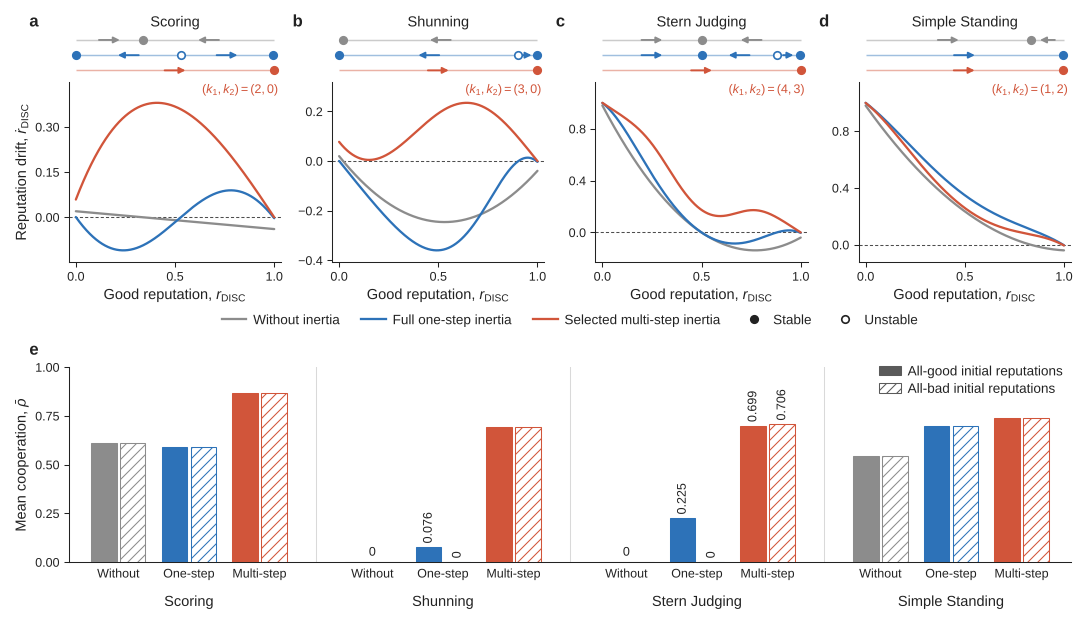

In [7]:
# Geometry (inches); the same sizes are reused for the bare single panels.
LEFT, RIGHT_EDGE, COL_GAP = 0.44, 7.12, 0.34
COL_W = (RIGHT_EDGE - LEFT - 3 * COL_GAP) / 4
PHASE_H, PHASE_GAP, DRIFT_H = 0.30, 0.03, 1.20
POP_W, POP_H = RIGHT_EDGE - LEFT, 1.30
FIG_HEIGHT = 4.12

def make_ed2_figure():
    fig = plt.figure(figsize=(FIG_WIDTH, FIG_HEIGHT))
    phase_top = FIG_HEIGHT - 0.17
    drift_y = phase_top - PHASE_H - PHASE_GAP - DRIFT_H
    for i, norm in enumerate(NORMS):
        x = LEFT + i * (COL_W + COL_GAP)
        phase = add_axes_in(fig, x, phase_top - PHASE_H, COL_W, PHASE_H)
        ax = add_axes_in(fig, x, drift_y, COL_W, DRIFT_H)
        draw_rates(phase, ax, norm, labels=True)
        panel_letter(phase, 'abcd'[i])
    legend_y = drift_y - 0.39
    fig.legend(handles=regime_legend_handles(), loc='center', ncol=5, columnspacing=1.6, handlelength=1.8,
               handletextpad=0.5, bbox_to_anchor=((LEFT + RIGHT_EDGE) / 2 / FIG_WIDTH, legend_y / FIG_HEIGHT))
    ax = add_axes_in(fig, LEFT, 0.42, POP_W, POP_H)
    draw_population(ax, labels=True)
    panel_letter(ax, 'e', dy=6)
    ax.legend(handles=initial_legend_handles(), loc='upper right', bbox_to_anchor=(1.0, 1.05), ncol=1,
              handlelength=1.6, handletextpad=0.5, labelspacing=0.35, borderaxespad=0.2)
    return fig

fig = make_ed2_figure()
save_figure(fig, FIGURES_OUT, 'Extended_Data_Figure2')
plt.show()
plt.close(fig)

## Bare single panels for PowerPoint

Tick marks only: no tick labels, axis labels, titles, legends, value labels or the $(k_1,k_2)$ note. Axes sizes equal those in the composite figure, so the panels can be inserted at 100 % and labelled in PowerPoint. The drift panels contain the phase strip above the drift axes, as in the composite. PNG files are 600 dpi; SVG keeps the vector graphics editable in PowerPoint (Insert ▸ Pictures, then *Convert to Shape*).

In [8]:
for i, norm in enumerate(NORMS):
    fig = plt.figure(figsize=(COL_W + 0.1, PHASE_H + PHASE_GAP + DRIFT_H + 0.1))
    ax = add_axes_in(fig, 0.05, 0.05, COL_W, DRIFT_H)
    phase = add_axes_in(fig, 0.05, 0.05 + DRIFT_H + PHASE_GAP, COL_W, PHASE_H)
    draw_rates(phase, ax, norm, labels=False)
    save_figure(fig, PANELS, f'panel_{"abcd"[i]}_{norm}_drift')
    plt.close(fig)

fig = plt.figure(figsize=(POP_W + 0.1, POP_H + 0.1))
draw_population(add_axes_in(fig, 0.05, 0.05, POP_W, POP_H), labels=False)
save_figure(fig, PANELS, 'panel_e_population_initial_reputation')
plt.close(fig)

# Panel e split by norm: one bare piece per norm, same y scale and bar widths as the full panel.
# Each piece has its own y axis (delete the extra ones in PowerPoint if the pieces are butted together).
GROUP_W = POP_W * GROUP / (3 * GROUP + 2.7 - (-0.7))
for norm in NORMS:
    fig = plt.figure(figsize=(GROUP_W + 0.1, POP_H + 0.1))
    draw_population(add_axes_in(fig, 0.05, 0.05, GROUP_W, POP_H), labels=False, only=norm)
    save_figure(fig, PANELS, f'panel_e_{norm}_population_initial_reputation')
    plt.close(fig)

# Legend-only strip, in case the legend is assembled in PowerPoint as well.
fig = plt.figure(figsize=(FIG_WIDTH, 0.4))
fig.legend(handles=regime_legend_handles(), loc='center', bbox_to_anchor=(0.5, 0.72), ncol=5, columnspacing=1.6,
           handlelength=1.8, handletextpad=0.5)
fig.legend(handles=initial_legend_handles(), loc='center', bbox_to_anchor=(0.5, 0.25), ncol=2, columnspacing=1.6,
           handlelength=1.6, handletextpad=0.5)
save_figure(fig, PANELS, 'legend_key')
plt.close(fig)

assert len(list(PANELS.glob('*.pdf'))) == len(list(PANELS.glob('*.svg'))) == len(list(PANELS.glob('*.png'))) == 10
print('Saved the composite figure, 9 bare panels (a-d, e, e per norm) + 1 legend strip (PDF, SVG, PNG) to', FIGURES_OUT.relative_to(ROOT))

Saved the composite figure, 9 bare panels (a-d, e, e per norm) + 1 legend strip (PDF, SVG, PNG) to figures/extended_data_figure2_restyled
